In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("fernando2rad/brain-tumor-mri-images-44c")

print("Path to dataset files:", path)

100%|██████████| 188M/188M [00:01<00:00, 141MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/fernando2rad/brain-tumor-mri-images-44c/versions/1


In [ ]:
import os
import kagglehub
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

# Charger le dataset depuis KaggleHub
dataset_path = kagglehub.dataset_download("fernando2rad/brain-tumor-mri-images-44c")
print("Dataset downloaded to:", dataset_path)

# Définir la taille des images
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Création d’un dataset d’images
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Normalisation
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# Améliorer la performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


Dataset downloaded to: /kaggle/input/brain-tumor-mri-images-44c
Found 4478 files belonging to 44 classes.
Using 3583 files for training.
Found 4478 files belonging to 44 classes.
Using 895 files for validation.


In [ ]:
# Charger temporairement pour obtenir les noms des classes
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = raw_train_ds.class_names
num_classes = len(class_names)

# Appliquer la normalisation sur les datasets originaux
train_ds = raw_train_ds.map(lambda x, y: (normalization_layer(x), y))

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))



Found 4478 files belonging to 44 classes.
Using 3583 files for training.
Found 4478 files belonging to 44 classes.
Using 895 files for validation.


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')  # 44 classes
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 44)             │        11,308 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,255,980 (84.90 MB)

 Trainable params: 22,255,980 (84.90 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
checkpoint_path = "/content/drive/MyDrive/brain_tumor/best_model.h5"


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_cb = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_accuracy',          # ou 'val_loss' si tu préfères
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[checkpoint_cb]
)
from tensorflow.keras.models import load_model
best_model = load_model(checkpoint_path)


Epoch 1/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.1320 - loss: 3.3794
Epoch 1: val_accuracy improved from -inf to 0.50615, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


112/112 ━━━━━━━━━━━━━━━━━━━━ 501s 4s/step - accuracy: 0.1330 - loss: 3.3754 - val_accuracy: 0.5061 - val_loss: 1.9768
Epoch 2/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5120 - loss: 1.8500
Epoch 2: val_accuracy improved from 0.50615 to 0.70726, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


112/112 ━━━━━━━━━━━━━━━━━━━━ 495s 4s/step - accuracy: 0.5125 - loss: 1.8478 - val_accuracy: 0.7073 - val_loss: 1.0662
Epoch 3/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7062 - loss: 1.0215
Epoch 3: val_accuracy improved from 0.70726 to 0.81117, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


112/112 ━━━━━━━━━━━━━━━━━━━━ 496s 4s/step - accuracy: 0.7066 - loss: 1.0203 - val_accuracy: 0.8112 - val_loss: 0.7268
Epoch 4/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8105 - loss: 0.6171
Epoch 4: val_accuracy improved from 0.81117 to 0.85587, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


112/112 ━━━━━━━━━━━━━━━━━━━━ 500s 4s/step - accuracy: 0.8107 - loss: 0.6165 - val_accuracy: 0.8559 - val_loss: 0.5421
Epoch 5/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8837 - loss: 0.3952
Epoch 5: val_accuracy improved from 0.85587 to 0.86480, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


...

112/112 ━━━━━━━━━━━━━━━━━━━━ 497s 4s/step - accuracy: 0.9297 - loss: 0.2538 - val_accuracy: 0.8804 - val_loss: 0.4638
Epoch 9/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9648 - loss: 0.1383
Epoch 9: val_accuracy improved from 0.88045 to 0.88603, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


112/112 ━━━━━━━━━━━━━━━━━━━━ 497s 4s/step - accuracy: 0.9647 - loss: 0.1383 - val_accuracy: 0.8860 - val_loss: 0.5705
Epoch 10/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9597 - loss: 0.1289
Epoch 10: val_accuracy improved from 0.88603 to 0.88939, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


112/112 ━━━━━━━━━━━━━━━━━━━━ 491s 4s/step - accuracy: 0.9597 - loss: 0.1289 - val_accuracy: 0.8894 - val_loss: 0.5211
Epoch 11/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9664 - loss: 0.1052
Epoch 11: val_accuracy improved from 0.88939 to 0.89721, saving model to /content/drive/MyDrive/brain_tumor/best_model.h5


112/112 ━━━━━━━━━━━━━━━━━━━━ 490s 4s/step - accuracy: 0.9664 - loss: 0.1052 - val_accuracy: 0.8972 - val_loss: 0.5059
Epoch 12/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9668 - loss: 0.1045
Epoch 12: val_accuracy did not improve from 0.89721
112/112 ━━━━━━━━━━━━━━━━━━━━ 492s 4s/step - accuracy: 0.9668 - loss: 0.1046 - val_accuracy: 0.8927 - val_loss: 0.4947
Epoch 13/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9593 - loss: 0.1323
Epoch 13: val_accuracy did not improve from 0.89721
112/112 ━━━━━━━━━━━━━━━━━━━━ 500s 4s/step - accuracy: 0.9593 - loss: 0.1321 - val_accuracy: 0.8972 - val_loss: 0.5147
Epoch 14/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9766 - loss: 0.1155
Epoch 14: val_accuracy did not improve from 0.89721
112/112 ━━━━━━━━━━━━━━━━━━━━ 500s 4s/step - accuracy: 0.9766 - loss: 0.1153 - val_accuracy: 0.8927 - val_loss: 0.5418
Epoch 15/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9692 - loss: 0.0970
Epoch 15: val_accuracy did n

112/112 ━━━━━━━━━━━━━━━━━━━━ 483s 4s/step - accuracy: 0.9704 - loss: 0.0920 - val_accuracy: 0.9017 - val_loss: 0.4857
Epoch 17/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9704 - loss: 0.1097
Epoch 17: val_accuracy did not improve from 0.90168
112/112 ━━━━━━━━━━━━━━━━━━━━ 485s 4s/step - accuracy: 0.9705 - loss: 0.1095 - val_accuracy: 0.8916 - val_loss: 0.5695
Epoch 18/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9787 - loss: 0.0692
Epoch 18: val_accuracy did not improve from 0.90168
112/112 ━━━━━━━━━━━━━━━━━━━━ 501s 4s/step - accuracy: 0.9787 - loss: 0.0692 - val_accuracy: 0.8883 - val_loss: 0.5471
Epoch 19/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9787 - loss: 0.0817
Epoch 19: val_accuracy did not improve from 0.90168
112/112 ━━━━━━━━━━━━━━━━━━━━ 474s 4s/step - accuracy: 0.9787 - loss: 0.0816 - val_accuracy: 0.8961 - val_loss: 0.5272
Epoch 20/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9809 - loss: 0.0718
Epoch 20: val_accuracy did n

Dataset downloaded to: /kaggle/input/brain-tumor-mri-images-44c
Found 4478 files belonging to 44 classes.
Using 3583 files for training.
Found 4478 files belonging to 44 classes.
Using 895 files for validation.
Classes détectées: ['Astrocitoma T1', 'Astrocitoma T1C+', 'Astrocitoma T2', 'Carcinoma T1', 'Carcinoma T1C+', 'Carcinoma T2', 'Ependimoma T1', 'Ependimoma T1C+', 'Ependimoma T2', 'Ganglioglioma T1', 'Ganglioglioma T1C+', 'Ganglioglioma T2', 'Germinoma T1', 'Germinoma T1C+', 'Germinoma T2', 'Glioblastoma T1', 'Glioblastoma T1C+', 'Glioblastoma T2', 'Granuloma T1', 'Granuloma T1C+', 'Granuloma T2', 'Meduloblastoma T1', 'Meduloblastoma T1C+', 'Meduloblastoma T2', 'Meningioma T1', 'Meningioma T1C+', 'Meningioma T2', 'Neurocitoma T1', 'Neurocitoma T1C+', 'Neurocitoma T2', 'Oligodendroglioma T1', 'Oligodendroglioma T1C+', 'Oligodendroglioma T2', 'Papiloma T1', 'Papiloma T1C+', 'Papiloma T2', 'Schwannoma T1', 'Schwannoma T1C+', 'Schwannoma T2', 'Tuberculoma T1', 'Tuberculoma T1C+', 'Tu

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │      9,472 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │     36,928 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_4[0][0]  

 Total params: 12,433,837 (47.43 MB)

 Trainable params: 12,424,237 (47.39 MB)

...

224/224 ━━━━━━━━━━━━━━━━━━━━ 1142s 5s/step - accuracy: 0.0648 - loss: 3.6048 - sparse_top_k_categorical_accuracy: 0.2706 - val_accuracy: 0.0872 - val_loss: 3.5359 - val_sparse_top_k_categorical_accuracy: 0.2961 - learning_rate: 0.0010

Epoch 2: LearningRateScheduler setting learning rate to 0.0010000000474974513.
Epoch 2/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0678 - loss: 3.5116 - sparse_top_k_categorical_accuracy: 0.2924
Epoch 2: val_accuracy did not improve from 0.08715


224/224 ━━━━━━━━━━━━━━━━━━━━ 1085s 5s/step - accuracy: 0.0678 - loss: 3.5115 - sparse_top_k_categorical_accuracy: 0.2925 - val_accuracy: 0.0872 - val_loss: 3.5317 - val_sparse_top_k_categorical_accuracy: 0.2883 - learning_rate: 0.0010

Epoch 3: LearningRateScheduler setting learning rate to 0.0010000000474974513.
Epoch 3/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0675 - loss: 3.5022 - sparse_top_k_categorical_accuracy: 0.3059
Epoch 3: val_accuracy did not improve from 0.08715


224/224 ━━━━━━━━━━━━━━━━━━━━ 1080s 5s/step - accuracy: 0.0675 - loss: 3.5022 - sparse_top_k_categorical_accuracy: 0.3058 - val_accuracy: 0.0872 - val_loss: 3.5243 - val_sparse_top_k_categorical_accuracy: 0.2883 - learning_rate: 0.0010

Epoch 4: LearningRateScheduler setting learning rate to 0.0010000000474974513.
Epoch 4/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0724 - loss: 3.4966 - sparse_top_k_categorical_accuracy: 0.3140
Epoch 4: val_accuracy did not improve from 0.08715


224/224 ━━━━━━━━━━━━━━━━━━━━ 1082s 5s/step - accuracy: 0.0724 - loss: 3.4966 - sparse_top_k_categorical_accuracy: 0.3140 - val_accuracy: 0.0872 - val_loss: 3.5225 - val_sparse_top_k_categorical_accuracy: 0.2883 - learning_rate: 0.0010

Epoch 5: LearningRateScheduler setting learning rate to 0.0010000000474974513.
Epoch 5/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0713 - loss: 3.4993 - sparse_top_k_categorical_accuracy: 0.3082
Epoch 5: val_accuracy did not improve from 0.08715


224/224 ━━━━━━━━━━━━━━━━━━━━ 1082s 5s/step - accuracy: 0.0713 - loss: 3.4992 - sparse_top_k_categorical_accuracy: 0.3082 - val_accuracy: 0.0872 - val_loss: 3.5204 - val_sparse_top_k_categorical_accuracy: 0.2883 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.


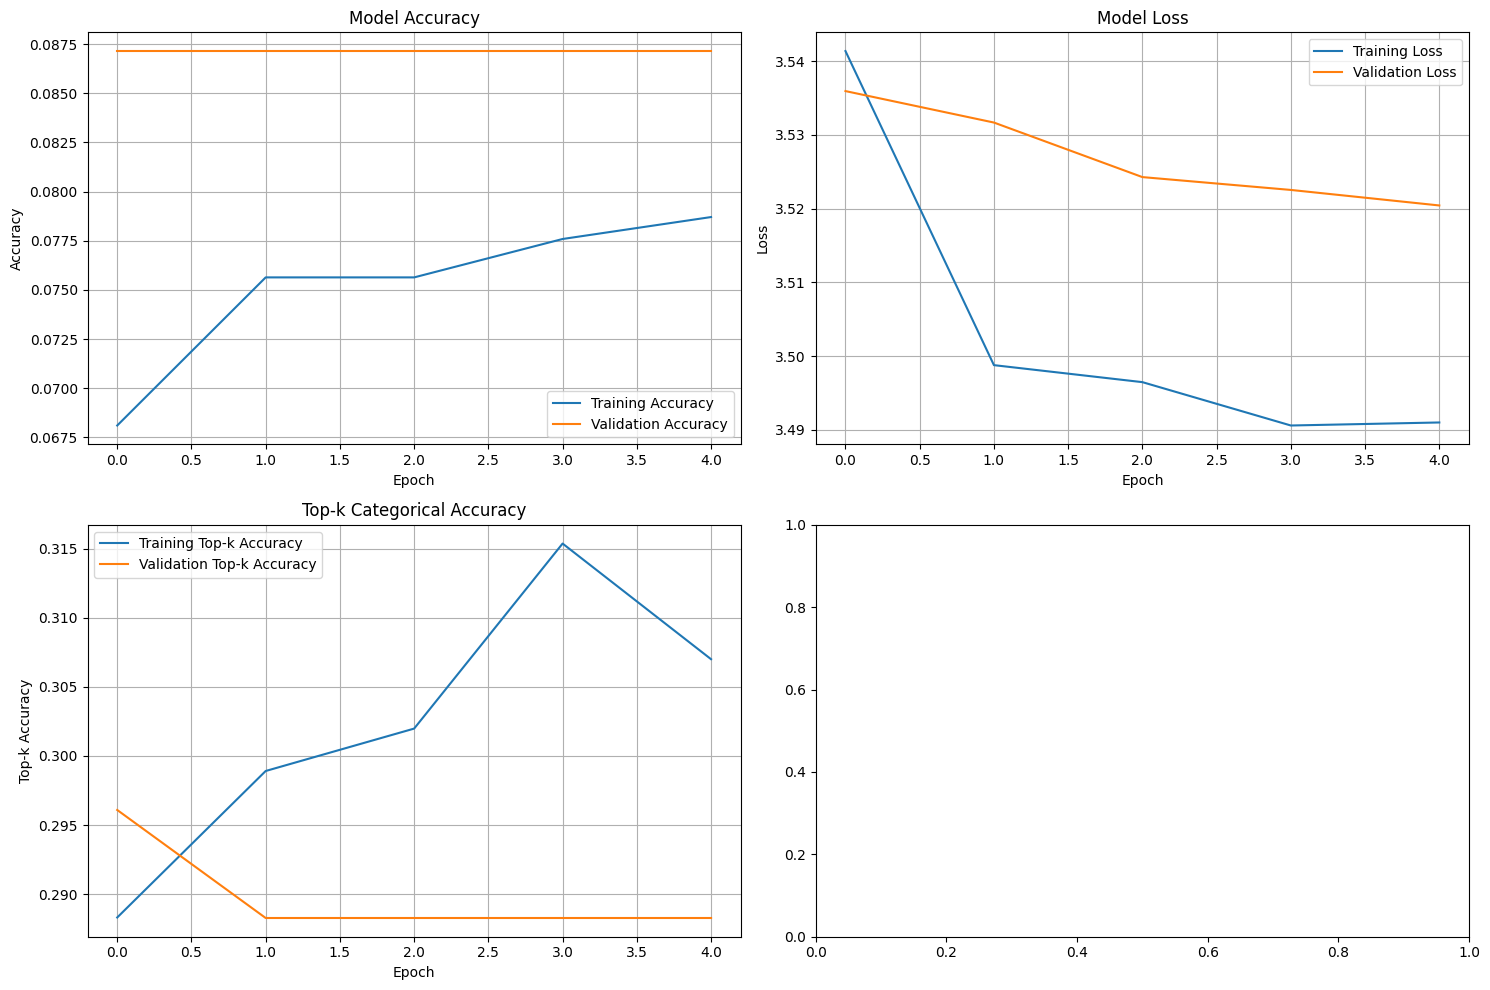


Évaluation du meilleur modèle:
56/56 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.1011 - loss: 3.4979 - sparse_top_k_categorical_accuracy: 0.2910
Test Accuracy: 0.0872
Test Top-k Accuracy: 0.2961


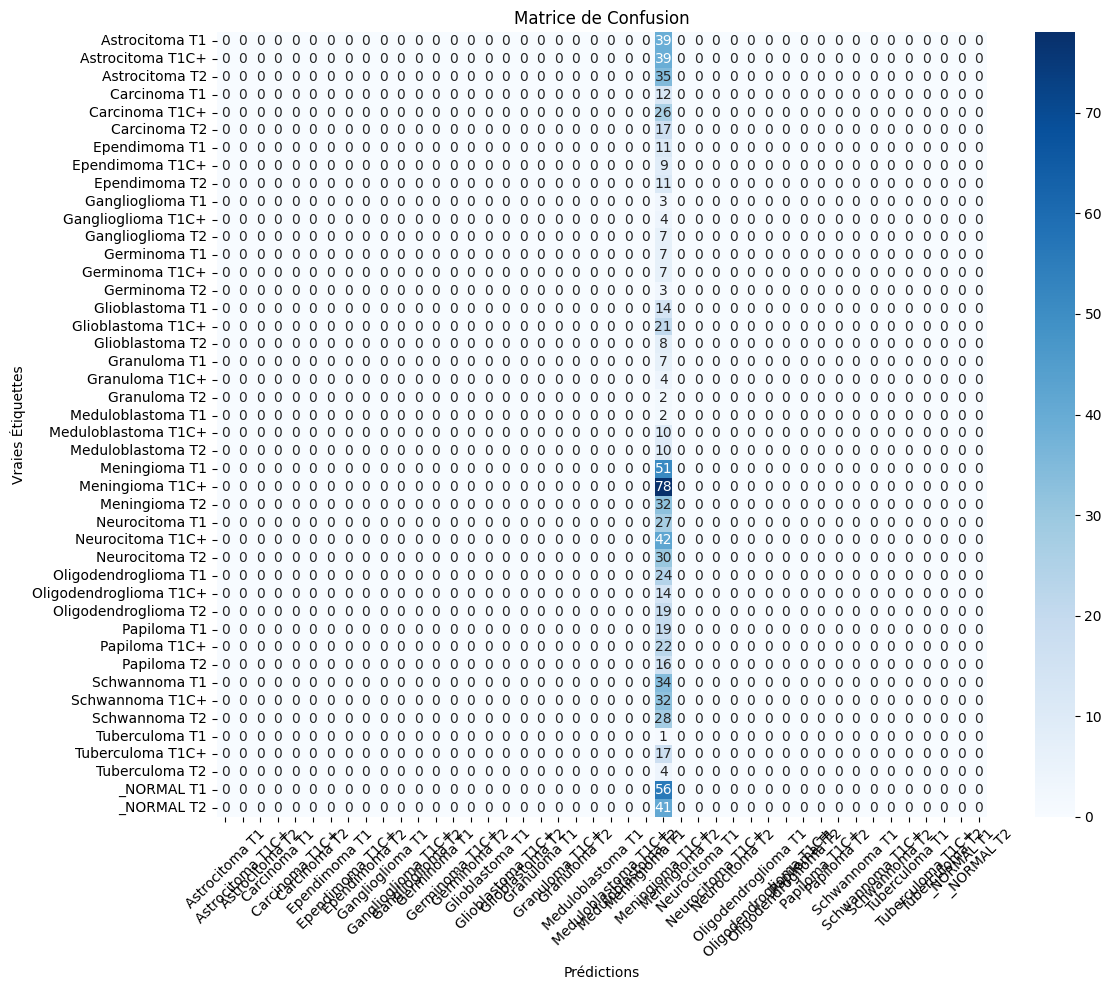


Rapport de classification:
                        precision    recall  f1-score   support

        Astrocitoma T1       0.00      0.00      0.00        39
      Astrocitoma T1C+       0.00      0.00      0.00        39
        Astrocitoma T2       0.00      0.00      0.00        35
          Carcinoma T1       0.00      0.00      0.00        12
        Carcinoma T1C+       0.00      0.00      0.00        26
          Carcinoma T2       0.00      0.00      0.00        17
         Ependimoma T1       0.00      0.00      0.00        11
       Ependimoma T1C+       0.00      0.00      0.00         9
         Ependimoma T2       0.00      0.00      0.00        11
      Ganglioglioma T1       0.00      0.00      0.00         3
    Ganglioglioma T1C+       0.00      0.00      0.00         4
      Ganglioglioma T2       0.00      0.00      0.00         7
          Germinoma T1       0.00      0.00      0.00         7
        Germinoma T1C+       0.00      0.00      0.00         7
          G

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import os
import kagglehub
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import EfficientNetB0, ResNet50V2
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, LearningRateScheduler
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 16  # Réduit pour des modèles plus complexes
SEED = 42
EPOCHS = 5

# Télécharger le dataset
dataset_path = kagglehub.dataset_download("fernando2rad/brain-tumor-mri-images-44c")
print("Dataset downloaded to:", dataset_path)

# Augmentation de données avancée
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomTranslation(0.1, 0.1),
])

# Création des datasets avec augmentation
def prepare_dataset(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                   num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x, y: (tf.keras.utils.normalize(x, axis=-1), y),
               num_parallel_calls=tf.data.AUTOTUNE)
    return ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# Chargement des données
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Classes détectées: {class_names}")
print(f"Nombre de classes: {num_classes}")

# Préparation des datasets
train_ds = prepare_dataset(train_ds, training=True)
val_ds = prepare_dataset(val_ds)

# Modèle 1: CNN Custom Avancé avec Attention
def create_advanced_cnn():
    inputs = layers.Input(shape=(224, 224, 3))

    # Premier bloc convolutionnel
    x = layers.Conv2D(64, (7, 7), strides=2, padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)

    # Blocs résiduel simplifiés
    def residual_block(x, filters, kernel_size=3, stride=1):
        shortcut = x

        x = layers.Conv2D(filters, kernel_size, strides=stride, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)

        x = layers.Conv2D(filters, kernel_size, padding='same')(x)
        x = layers.BatchNormalization()(x)

        if stride != 1 or shortcut.shape[-1] != filters:
            shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same')(shortcut)
            shortcut = layers.BatchNormalization()(shortcut)

        x = layers.Add()([x, shortcut])
        x = layers.Activation('relu')(x)
        return x

    # Séquence de blocs résiduel
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)
    x = residual_block(x, 512, stride=2)
    x = residual_block(x, 512)

    # Mécanisme d'attention spatial
    def spatial_attention(feature_map):
        # Attention par canal
        avg_pool = layers.GlobalAveragePooling2D(keepdims=True)(feature_map)
        max_pool = layers.GlobalMaxPooling2D(keepdims=True)(feature_map)

        concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])
        attention = layers.Conv2D(1, 7, padding='same', activation='sigmoid')(concat)

        return layers.Multiply()([feature_map, attention])

    x = spatial_attention(x)

    # Pooling adaptatif
    x = layers.GlobalAveragePooling2D()(x)

    # Classification head avec dropout progressif
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

# Modèle 2: Transfer Learning avec EfficientNet
def create_transfer_learning_model():
    base_model = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Dégeler les dernières couches pour fine-tuning
    base_model.trainable = True
    fine_tune_at = len(base_model.layers) - 20

    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)

    # Tête de classification personnalisée
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

# Choisir le modèle (changez ici pour tester différents modèles)
MODEL_TYPE = "custom"  # "custom" ou "transfer"

if MODEL_TYPE == "custom":
    model = create_advanced_cnn()
    print("Modèle CNN personnalisé créé")
else:
    model = create_transfer_learning_model()
    print("Modèle Transfer Learning créé")

# Fonction de planification du taux d'apprentissage
def scheduler(epoch, lr):
    if epoch < 10:
        return lr
    elif epoch < 20:
        return lr * 0.5
    elif epoch < 35:
        return lr * 0.1
    else:
        return lr * 0.01

# Optimiseur avec paramètres personnalisés
if MODEL_TYPE == "transfer":
    optimizer = optimizers.Adam(learning_rate=0.0001)
else:
    optimizer = optimizers.Adam(learning_rate=0.001)

# Compilation avec métriques supplémentaires
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy', 'sparse_top_k_categorical_accuracy']
)

model.summary()

# Callbacks avancés
from google.colab import drive
drive.mount('/content/drive')

checkpoint_path = "/content/drive/MyDrive/brain_tumor/advanced_model_{epoch:02d}_{val_accuracy:.4f}.h5"
best_model_path = "/content/drive/MyDrive/brain_tumor/best_advanced_model.h5"

callbacks = [
    ModelCheckpoint(
        filepath=best_model_path,
        monitor='val_accuracy',
        save_best_only=True,
        save_weights_only=False,
        verbose=1,
        mode='max'
    ),
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_accuracy',
        save_best_only=False,
        save_weights_only=False,
        verbose=0,
        save_freq='epoch'  # Sauvegarder chaque epoch
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=5,
        min_lr=1e-7,
        verbose=1
    ),
    LearningRateScheduler(scheduler, verbose=1)
]

# Entraînement
print("Début de l'entraînement...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# Sauvegarde de l'historique
history_path = "/content/drive/MyDrive/brain_tumor/training_history.npy"
np.save(history_path, history.history)

# Fonction pour visualiser les résultats
def plot_training_history(history):
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Accuracy
    axes[0, 0].plot(history.history['accuracy'], label='Training Accuracy')
    axes[0, 0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[0, 0].set_title('Model Accuracy')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    # Loss
    axes[0, 1].plot(history.history['loss'], label='Training Loss')
    axes[0, 1].plot(history.history['val_loss'], label='Validation Loss')
    axes[0, 1].set_title('Model Loss')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True)

    # Top-k Accuracy
    if 'sparse_top_k_categorical_accuracy' in history.history:
        axes[1, 0].plot(history.history['sparse_top_k_categorical_accuracy'], label='Training Top-k Accuracy')
        axes[1, 0].plot(history.history['val_sparse_top_k_categorical_accuracy'], label='Validation Top-k Accuracy')
        axes[1, 0].set_title('Top-k Categorical Accuracy')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Top-k Accuracy')
        axes[1, 0].legend()
        axes[1, 0].grid(True)

    # Learning Rate
    if 'lr' in history.history:
        axes[1, 1].plot(history.history['lr'], label='Learning Rate')
        axes[1, 1].set_title('Learning Rate Schedule')
        axes[1, 1].set_xlabel('Epoch')
        axes[1, 1].set_ylabel('Learning Rate')
        axes[1, 1].set_yscale('log')
        axes[1, 1].legend()
        axes[1, 1].grid(True)

    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/brain_tumor/training_plots.png', dpi=300, bbox_inches='tight')
    plt.show()

# Visualiser les résultats
plot_training_history(history)

# Charger le meilleur modèle et évaluer
best_model = tf.keras.models.load_model(best_model_path)

# Évaluation détaillée
print("\nÉvaluation du meilleur modèle:")
test_loss, test_acc, test_top_k = best_model.evaluate(val_ds, verbose=1)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Top-k Accuracy: {test_top_k:.4f}")

# Prédictions pour matrice de confusion
y_pred = []
y_true = []

for images, labels in val_ds:
    predictions = best_model.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

# Matrice de confusion
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de Confusion')
plt.xlabel('Prédictions')
plt.ylabel('Vraies Étiquettes')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/brain_tumor/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Rapport de classification
print("\nRapport de classification:")
print(classification_report(y_true, y_pred, target_names=class_names))

print(f"\nModèle sauvegardé dans: {best_model_path}")
print("Entraînement terminé!")

In [ ]:
pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.9/319.9 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 104.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 112.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 120.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.5 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.31.1
    Uninstalling protobuf-6.31.1:
      Successfully uninstalled protobuf-6.31.1


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🧠 ÉVALUATION DU MODÈLE MULTI-CLASSES (44 CLASSES)
📊 Nombre de classes: 44
🏥 Types de tumeurs et séquences IRM:
   0: Astrocitoma T1
   1: Astrocitoma T1C+
   2: Astrocitoma T2
   3: Carcinoma T1
   4: Carcinoma T1C+
   5: Carcinoma T2
   6: Ependimoma T1
   7: Ependimoma T1C+
   8: Ependimoma T2
   9: Ganglioglioma T1
  10: Ganglioglioma T1C+
  11: Ganglioglioma T2
  12: Germinoma T1
  13: Germinoma T1C+
  14: Germinoma T2
  15: Glioblastoma T1
  16: Glioblastoma T1C+
  17: Glioblastoma T2
  18: Granuloma T1
  19: Granuloma T1C+
  20: Granuloma T2
  21: Meduloblastoma T1
  22: Meduloblastoma T1C+
  23: Meduloblastoma T2
  24: Meningioma T1
  25: Meningioma T1C+
  26: Meningioma T2
  27: Neurocitoma T1
  28: Neurocitoma T1C+
  29: Neurocitoma T2
  30: Oligodendroglioma T1
  31: Oligodendroglioma T1C+
  32: Oligodendroglioma T2
  33: Papiloma T1
  34: Papiloma 

🧠 Modèle multi-classes chargé avec succès!
📊 Architecture du modèle:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 44)             │        11,308 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,255,982 (84.90 MB)

...

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

🎯 Forme de sortie: (None, 44)

📁 Préparation du dataset de test...
🔄 Mapping des classes:
  glioma → Glioblastoma T2 (index 17)
  meningioma → Meningioma T2 (index 26)
  pituitary → Papiloma T2 (index 35)
  notumor → _NORMAL T2 (index 43)
✅ Dataset préparé: 1311 images

🔍 DÉTECTION DE LA TAILLE D'IMAGE:
📏 Forme d'entrée du modèle: (None, 224, 224, 3)
🖼️  Taille d'image détectée: (224, 224)
Found 1311 images belonging to 4 classes.
🔍 Générateur créé: 1311 images
📂 Classes détectées: 4
🏷️  Index des classes: {'Glioblastoma T2': 0, 'Meningioma T2': 1, 'Papiloma T2': 2, '_NORMAL T2': 3}

🚀 Prédictions multi-classes en cours...
⏳ Génération des prédictions...


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


41/41 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step
✅ Prédictions terminées!
📊 Forme des probabilités: (1311, 44)
📈 Classes prédites uniques: [ 0  1  2  4  6  7  8  9 10 14 15 16 17 18 19 22 24 25 26 27 28 29 30 31
 32 33 34 35 36 37 38 40 41 42 43]
📈 Classes vraies uniques: [17 26 35 43]

📊 RÉSULTATS DE L'ÉVALUATION MULTI-CLASSES
🎯 Accuracy globale: 0.0549 (5.49%)

📊 Matrice de confusion (35 classes actives):
                        Astrocitoma T1  Astrocitoma T1C+  Astrocitoma T2  \
Astrocitoma T1                       0                 0               0   
Astrocitoma T1C+                     0                 0               0   
Astrocitoma T2                       0                 0               0   
Carcinoma T1C+                       0                 0               0   
Ependimoma T1                        0                 0               0   
Ependimoma T1C+                      0                 0               0   
Ependimoma T2                        0                 0           

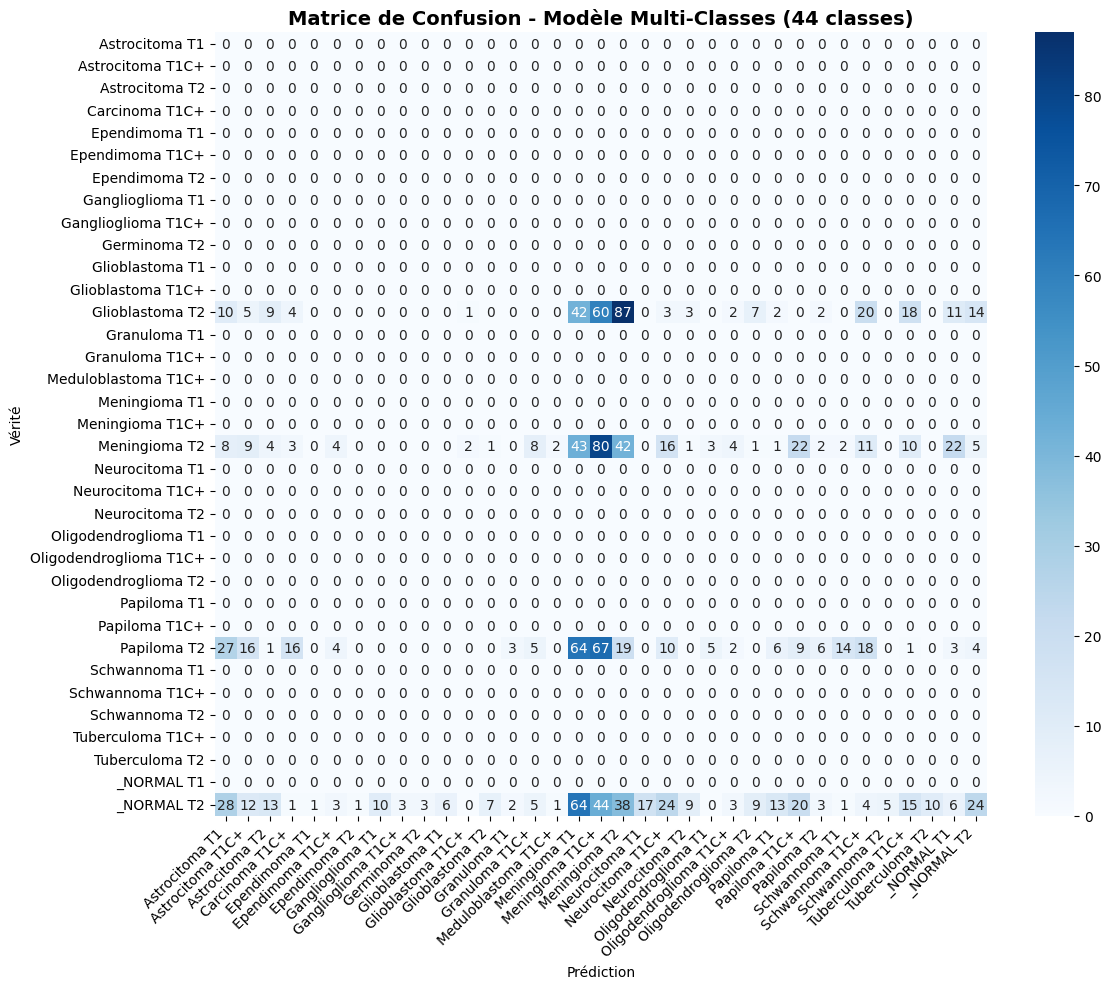

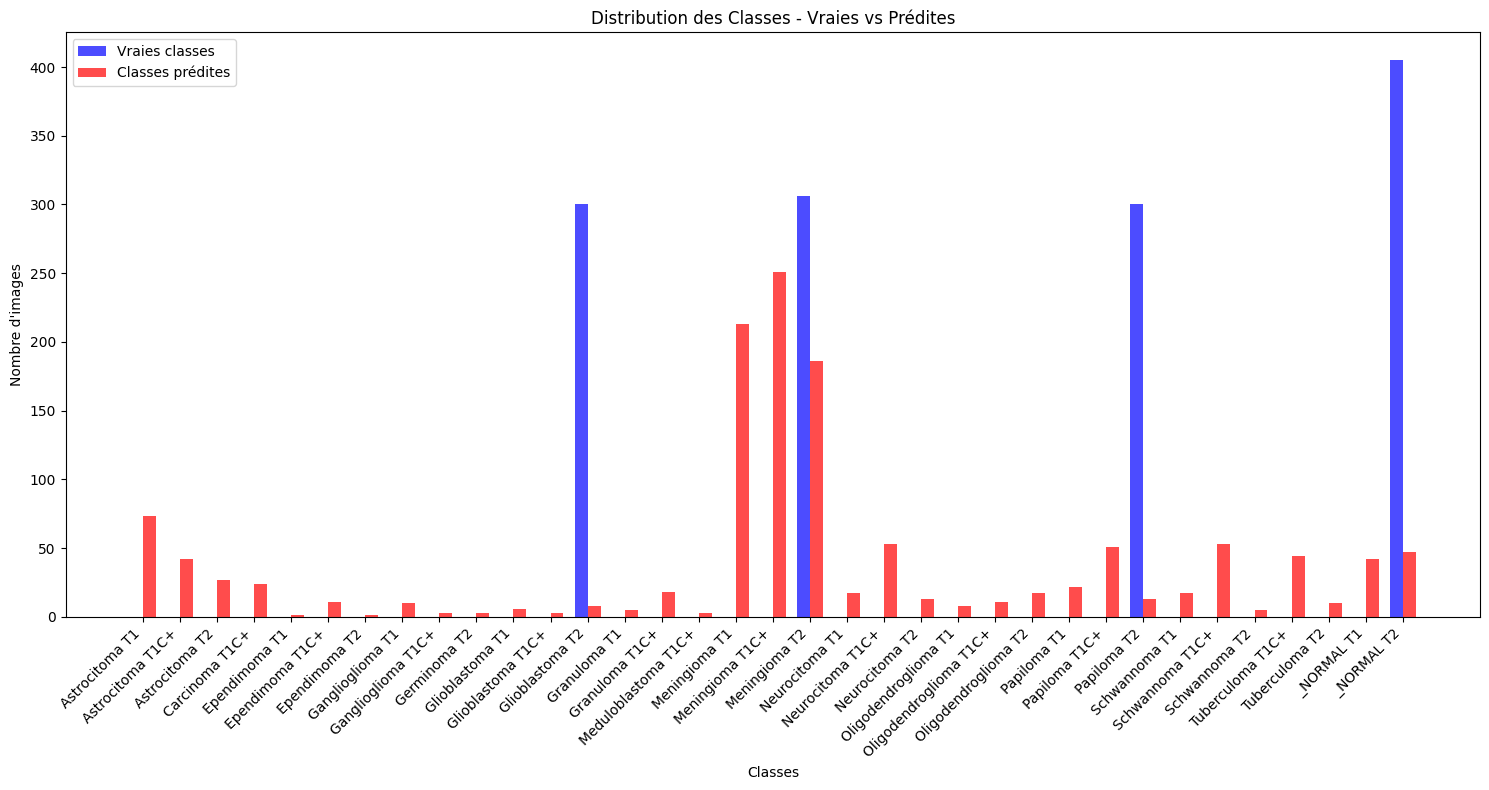


🎯 ANALYSE DES PROBABILITÉS:

Image 1:
  Vraie classe: Glioblastoma T2
  Classe prédite: Meningioma T1C+ (prob: 0.248)
  Top 5 probabilités:
    1. Meningioma T1C+: 0.248
    2. Meningioma T1: 0.231
    3. Meningioma T2: 0.123
    4. Glioblastoma T2: 0.076
    5. Meduloblastoma T1: 0.073

Image 2:
  Vraie classe: Glioblastoma T2
  Classe prédite: Tuberculoma T1C+ (prob: 0.428)
  Top 5 probabilités:
    1. Tuberculoma T1C+: 0.428
    2. Schwannoma T1C+: 0.246
    3. Tuberculoma T1: 0.101
    4. Ependimoma T1C+: 0.053
    5. Granuloma T1C+: 0.036

Image 3:
  Vraie classe: Glioblastoma T2
  Classe prédite: Tuberculoma T1C+ (prob: 0.558)
  Top 5 probabilités:
    1. Tuberculoma T1C+: 0.558
    2. Meningioma T1C+: 0.091
    3. Meningioma T1: 0.076
    4. _NORMAL T1: 0.057
    5. Schwannoma T1: 0.039

Image 4:
  Vraie classe: Glioblastoma T2
  Classe prédite: _NORMAL T2 (prob: 0.359)
  Top 5 probabilités:
    1. _NORMAL T2: 0.359
    2. Papiloma T1C+: 0.134
    3. Astrocitoma T1C+: 0.089
   

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import os
import shutil
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf
from google.colab import drive
import kagglehub
import pandas as pd
from collections import Counter

# Monter Google Drive pour accéder au modèle sauvegardé
drive.mount('/content/drive')

# =============================================
# 1. DÉFINITION DES 44 CLASSES
# =============================================

# Liste complète des 44 classes de votre modèle
CLASS_NAMES = [
    'Astrocitoma T1', 'Astrocitoma T1C+', 'Astrocitoma T2',
    'Carcinoma T1', 'Carcinoma T1C+', 'Carcinoma T2',
    'Ependimoma T1', 'Ependimoma T1C+', 'Ependimoma T2',
    'Ganglioglioma T1', 'Ganglioglioma T1C+', 'Ganglioglioma T2',
    'Germinoma T1', 'Germinoma T1C+', 'Germinoma T2',
    'Glioblastoma T1', 'Glioblastoma T1C+', 'Glioblastoma T2',
    'Granuloma T1', 'Granuloma T1C+', 'Granuloma T2',
    'Meduloblastoma T1', 'Meduloblastoma T1C+', 'Meduloblastoma T2',
    'Meningioma T1', 'Meningioma T1C+', 'Meningioma T2',
    'Neurocitoma T1', 'Neurocitoma T1C+', 'Neurocitoma T2',
    'Oligodendroglioma T1', 'Oligodendroglioma T1C+', 'Oligodendroglioma T2',
    'Papiloma T1', 'Papiloma T1C+', 'Papiloma T2',
    'Schwannoma T1', 'Schwannoma T1C+', 'Schwannoma T2',
    'Tuberculoma T1', 'Tuberculoma T1C+', 'Tuberculoma T2',
    '_NORMAL T1', '_NORMAL T2'
]

print("🧠 ÉVALUATION DU MODÈLE MULTI-CLASSES (44 CLASSES)")
print("="*60)
print(f"📊 Nombre de classes: {len(CLASS_NAMES)}")
print("🏥 Types de tumeurs et séquences IRM:")
for i, cls in enumerate(CLASS_NAMES):
    print(f"  {i:2d}: {cls}")

# =============================================
# 2. CHARGEMENT DU MODÈLE MULTI-CLASSES
# =============================================

def load_multiclass_model():
    """Charge le modèle multi-classes depuis le chemin donné"""
    model_path = "/content/drive/MyDrive/brain_tumor/best_model.h5"

    if os.path.exists(model_path):
        print(f"✅ Chargement du modèle depuis: {model_path}")
        try:
            model = tf.keras.models.load_model(model_path)
            print(f"🧠 Modèle multi-classes chargé avec succès!")
            print(f"📊 Architecture du modèle:")
            model.summary()

            # Vérifier que c'est bien un modèle 44 classes
            output_shape = model.output_shape
            print(f"🎯 Forme de sortie: {output_shape}")
            if output_shape[-1] != 44:
                print(f"⚠️  ATTENTION: Le modèle a {output_shape[-1]} sorties, attendu 44")

            return model
        except Exception as e:
            print(f"❌ Erreur lors du chargement: {e}")
            return None
    else:
        print(f"❌ Modèle non trouvé à: {model_path}")
        return None

# Charger le modèle
print("\n🔍 Chargement du modèle multi-classes...")
best_model = load_multiclass_model()

if best_model is None:
    print("❌ Impossible de continuer sans modèle.")
    exit()

# =============================================
# 3. PRÉPARATION DU DATASET DE TEST MULTI-CLASSES
# =============================================

# Pour ce test, nous utiliserons le dataset Brain Tumor MRI Dataset (4 classes)
# et mapperons vers votre système de 44 classes
multi_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
if "brain_tumor_dataset" in os.listdir(multi_path):
    multi_path = os.path.join(multi_path, "brain_tumor_dataset")

multi_test_path = os.path.join(multi_path, "Testing")

# Créer structure de test adaptée
test_path = "/kaggle/working/multiclass_test"
os.makedirs(test_path, exist_ok=True)

# Mapping des classes du dataset vers vos 44 classes
# Nous utiliserons quelques classes représentatives pour la démonstration
CLASS_MAPPING = {
    'glioma': 'Glioblastoma T2',        # Classe 17
    'meningioma': 'Meningioma T2',      # Classe 26
    'pituitary': 'Papiloma T2',         # Classe 35 (approximation)
    'notumor': '_NORMAL T2'             # Classe 43
}

print(f"\n📁 Préparation du dataset de test...")
print(f"🔄 Mapping des classes:")
for old_cls, new_cls in CLASS_MAPPING.items():
    new_idx = CLASS_NAMES.index(new_cls)
    print(f"  {old_cls} → {new_cls} (index {new_idx})")

# Copier et organiser les images
file_info = []
for old_class, new_class in CLASS_MAPPING.items():
    old_path = os.path.join(multi_test_path, old_class)
    new_path = os.path.join(test_path, new_class)
    os.makedirs(new_path, exist_ok=True)

    if os.path.exists(old_path):
        for fname in os.listdir(old_path):
            if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                src = os.path.join(old_path, fname)
                dst = os.path.join(new_path, fname)
                shutil.copy2(src, dst)
                file_info.append({
                    'filename': fname,
                    'original_class': old_class,
                    'mapped_class': new_class,
                    'class_index': CLASS_NAMES.index(new_class)
                })

print(f"✅ Dataset préparé: {len(file_info)} images")

# =============================================
# 4. DÉTECTION AUTOMATIQUE DE LA TAILLE D'IMAGE
# =============================================

# Détecter la taille d'entrée du modèle
input_shape = best_model.input_shape
expected_height = input_shape[1]
expected_width = input_shape[2]
img_size = (expected_height, expected_width)

print(f"\n🔍 DÉTECTION DE LA TAILLE D'IMAGE:")
print(f"📏 Forme d'entrée du modèle: {input_shape}")
print(f"🖼️  Taille d'image détectée: {img_size}")

batch_size = 32

datagen_test = ImageDataGenerator(rescale=1./255)

test_generator = datagen_test.flow_from_directory(
    test_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',  # Changé pour multi-classes
    shuffle=False
)

print(f"🔍 Générateur créé: {test_generator.samples} images")
print(f"📂 Classes détectées: {len(test_generator.class_indices)}")
print(f"🏷️  Index des classes: {test_generator.class_indices}")

# =============================================
# 6. PRÉDICTIONS MULTI-CLASSES AVEC GESTION D'ERREURS
# =============================================

print("\n🚀 Prédictions multi-classes en cours...")

try:
    # Prédictions (probabilités pour chaque classe)
    print("⏳ Génération des prédictions...")
    preds_prob = best_model.predict(test_generator, verbose=1)

    # Classe prédite (index de la probabilité maximale)
    preds = np.argmax(preds_prob, axis=1)

    # Vraies classes (adapter selon le mapping)
    true_labels_local = test_generator.classes  # Index locaux (0,1,2,3)

    # Convertir les index locaux vers les vrais index des 44 classes
    local_to_global = {}
    for local_name, local_idx in test_generator.class_indices.items():
        global_idx = CLASS_NAMES.index(local_name)
        local_to_global[local_idx] = global_idx

    true_labels = np.array([local_to_global[local_idx] for local_idx in true_labels_local])

    print(f"✅ Prédictions terminées!")
    print(f"📊 Forme des probabilités: {preds_prob.shape}")
    print(f"📈 Classes prédites uniques: {np.unique(preds)}")
    print(f"📈 Classes vraies uniques: {np.unique(true_labels)}")

    # Vérifier la cohérence
    if len(preds) != len(true_labels):
        print(f"⚠️  ATTENTION: Longueurs différentes - preds: {len(preds)}, true: {len(true_labels)}")

    predictions_success = True

except Exception as e:
    print(f"❌ Erreur lors des prédictions: {e}")
    print(f"\n🔧 DIAGNOSTIC DU PROBLÈME:")
    print(f"   📏 Taille d'entrée attendue: {input_shape}")
    print(f"   🖼️  Taille configurée: {img_size}")
    print(f"   📊 Forme de sortie: {best_model.output_shape}")

    # Essayer avec une image de test pour voir la forme exacte
    try:
        test_batch = next(iter(test_generator))
        print(f"   🎯 Forme du batch de test: {test_batch[0].shape}")
    except Exception as batch_error:
        print(f"   ❌ Impossible de lire le batch: {batch_error}")

    predictions_success = False

# Continuer seulement si les prédictions ont réussi
if not predictions_success:
    print("\n❌ IMPOSSIBLE DE CONTINUER SANS PRÉDICTIONS")
    print("🔧 SOLUTIONS POSSIBLES:")
    print("1. Vérifiez la taille d'image d'entraînement de votre modèle")
    print("2. Le modèle attend probablement des images 224x224 ou 256x256")
    print("3. Rechargez le modèle et vérifiez input_shape")
    exit()

# =============================================
# 7. MÉTRIQUES DE PERFORMANCE
# =============================================

# Accuracy globale
accuracy = accuracy_score(true_labels, preds)

print(f"\n📊 RÉSULTATS DE L'ÉVALUATION MULTI-CLASSES")
print("="*60)
print(f"🎯 Accuracy globale: {accuracy:.4f} ({accuracy*100:.2f}%)")

# Matrice de confusion (seulement pour les classes présentes)
unique_labels = np.unique(np.concatenate([true_labels, preds]))
cm = confusion_matrix(true_labels, preds, labels=unique_labels)

print(f"\n📊 Matrice de confusion ({len(unique_labels)} classes actives):")
present_class_names = [CLASS_NAMES[i] for i in unique_labels]

# Créer un DataFrame pour une meilleure visualisation
cm_df = pd.DataFrame(cm, index=present_class_names, columns=present_class_names)
print(cm_df)

# =============================================
# 7. ANALYSE DÉTAILLÉE PAR CLASSE
# =============================================

print(f"\n🔍 ANALYSE PAR CLASSE:")
print("-" * 60)

for i, true_idx in enumerate(unique_labels):
    class_name = CLASS_NAMES[true_idx]

    # Métriques pour cette classe
    true_mask = (true_labels == true_idx)
    pred_mask = (preds == true_idx)

    tp = np.sum(true_mask & pred_mask)
    fp = np.sum(~true_mask & pred_mask)
    fn = np.sum(true_mask & ~pred_mask)
    tn = np.sum(~true_mask & ~pred_mask)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    print(f"\n🏥 {class_name} (Index {true_idx}):")
    print(f"   📊 TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    print(f"   📈 Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")

# =============================================
# 8. VISUALISATIONS
# =============================================

# 1. Matrice de confusion avec heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title('Matrice de Confusion - Modèle Multi-Classes (44 classes)', fontsize=14, fontweight='bold')
plt.xlabel('Prédiction')
plt.ylabel('Vérité')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Distribution des prédictions
plt.figure(figsize=(15, 8))

# Compter les prédictions par classe
pred_counts = Counter(preds)
true_counts = Counter(true_labels)

# Graphique des distributions
x_pos = np.arange(len(unique_labels))
pred_values = [pred_counts.get(idx, 0) for idx in unique_labels]
true_values = [true_counts.get(idx, 0) for idx in unique_labels]

width = 0.35
plt.bar(x_pos - width/2, true_values, width, label='Vraies classes', alpha=0.7, color='blue')
plt.bar(x_pos + width/2, pred_values, width, label='Classes prédites', alpha=0.7, color='red')

plt.xlabel('Classes')
plt.ylabel('Nombre d\'images')
plt.title('Distribution des Classes - Vraies vs Prédites')
plt.xticks(x_pos, [CLASS_NAMES[i] for i in unique_labels], rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

# 3. Top 5 des probabilités par prédiction
print(f"\n🎯 ANALYSE DES PROBABILITÉS:")
for i in range(min(5, len(preds))):  # Montrer 5 exemples
    top5_indices = np.argsort(preds_prob[i])[-5:][::-1]
    top5_probs = preds_prob[i][top5_indices]

    print(f"\nImage {i+1}:")
    print(f"  Vraie classe: {CLASS_NAMES[true_labels[i]]}")
    print(f"  Classe prédite: {CLASS_NAMES[preds[i]]} (prob: {preds_prob[i][preds[i]]:.3f})")
    print(f"  Top 5 probabilités:")
    for j, (idx, prob) in enumerate(zip(top5_indices, top5_probs)):
        print(f"    {j+1}. {CLASS_NAMES[idx]}: {prob:.3f}")

# =============================================
# 9. RAPPORT DE CLASSIFICATION
# =============================================

print(f"\n📋 RAPPORT DE CLASSIFICATION DÉTAILLÉ:")
print("="*70)

# Générer le rapport seulement pour les classes présentes
target_names = [CLASS_NAMES[i] for i in unique_labels]
report = classification_report(true_labels, preds,
                             labels=unique_labels,
                             target_names=target_names)
print(report)

# =============================================
# 10. SAUVEGARDE DES RÉSULTATS
# =============================================

# Créer le dossier de résultats
results_dir = '/content/drive/MyDrive/brain_tumor'
os.makedirs(results_dir, exist_ok=True)

# Sauvegarder les résultats
results_path = os.path.join(results_dir, 'multiclass_evaluation_results.txt')
with open(results_path, 'w', encoding='utf-8') as f:
    f.write("="*70 + "\n")
    f.write("ÉVALUATION DU MODÈLE MULTI-CLASSES (44 CLASSES)\n")
    f.write("="*70 + "\n")
    f.write(f"Modèle évalué: /content/drive/MyDrive/brain_tumor/best_model.h5\n")
    f.write(f"Date: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")

    f.write("CLASSES DU MODÈLE (44 classes):\n")
    for i, cls in enumerate(CLASS_NAMES):
        f.write(f"  {i:2d}: {cls}\n")

    f.write(f"\nACCURACY GLOBALE: {accuracy:.4f} ({accuracy*100:.2f}%)\n\n")

    f.write("MATRICE DE CONFUSION:\n")
    f.write(str(cm_df) + "\n\n")

    f.write("RAPPORT DE CLASSIFICATION:\n")
    f.write(report + "\n")

    f.write("\nCLASSES TESTÉES:\n")
    for old_cls, new_cls in CLASS_MAPPING.items():
        f.write(f"  {old_cls} → {new_cls}\n")

# Sauvegarder les prédictions
predictions_path = os.path.join(results_dir, 'multiclass_predictions.npz')
np.savez(predictions_path,
         predictions=preds,
         probabilities=preds_prob,
         true_labels=true_labels,
         class_names=CLASS_NAMES,
         unique_labels=unique_labels)

print(f"\n💾 Résultats sauvegardés:")
print(f"  📄 Rapport: {results_path}")
print(f"  📊 Prédictions: {predictions_path}")

# =============================================
# 11. RÉSUMÉ FINAL
# =============================================

print(f"\n🏆 RÉSUMÉ DE L'ÉVALUATION")
print("="*50)
print(f"🧠 Modèle: 44 classes de tumeurs cérébrales")
print(f"📊 Images testées: {len(true_labels)}")
print(f"🎯 Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"📈 Classes actives: {len(unique_labels)}/44")
print(f"🔍 Classes testées:")
for cls in present_class_names:
    print(f"   - {cls}")

print(f"\n✅ Évaluation terminée avec succès!")

# Suggestions d'amélioration
print(f"\n💡 SUGGESTIONS:")
print("1. Testez avec un dataset complet des 44 classes")
print("2. Utilisez des techniques d'augmentation de données")
print("3. Analysez les confusions entre classes similaires")
print("4. Considérez un fine-tuning sur des classes spécifiques")

In [ ]:
pip install tensorflow keras scikit-learn matplotlib seaborn opencv-python numpy pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 83.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.9/319.9 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 120.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 115.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 123.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 6.7 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.31.1
    Uninstalling protobuf-6.31.1:
      Successfully uninstalled protobuf-6.31.1


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import EfficientNetB5, DenseNet201, InceptionResNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from sklearn.model_selection import train_test_split
import cv2
import os
from pathlib import Path

class BrainTumorClassifier:
    """
    Modèle de classification de tumeurs cérébrales basé sur des IRM
    Supporte plusieurs architectures de deep learning et classification multi-classes
    """

    def __init__(self, img_height=224, img_width=224, num_classes=4):
        self.img_height = img_height
        self.img_width = img_width
        self.num_classes = num_classes
        self.model = None
        self.history = None

        # Définition des classes pour le dataset BraTS/standard
        self.class_names = ['No Tumor', 'Glioma', 'Meningioma', 'Pituitary']

    def create_ensemble_model(self, base_models=['efficientnet', 'densenet', 'inception']):
        """
        Crée un modèle ensemble utilisant plusieurs architectures pré-entraînées
        """
        inputs = layers.Input(shape=(self.img_height, self.img_width, 3))

        # Préprocessing standardisé
        x = layers.Lambda(lambda x: tf.cast(x, tf.float32) / 255.0)(inputs)

        models_outputs = []

        for base_model_name in base_models:
            if base_model_name == 'efficientnet':
                base_model = EfficientNetB5(
                    weights='imagenet',
                    include_top=False,
                    input_shape=(self.img_height, self.img_width, 3)
                )
            elif base_model_name == 'densenet':
                base_model = DenseNet201(
                    weights='imagenet',
                    include_top=False,
                    input_shape=(self.img_height, self.img_width, 3)
                )
            elif base_model_name == 'inception':
                base_model = InceptionResNetV2(
                    weights='imagenet',
                    include_top=False,
                    input_shape=(self.img_height, self.img_width, 3)
                )

            # Déblocage des dernières couches pour le fine-tuning
            base_model.trainable = True
            for layer in base_model.layers[:-20]:
                layer.trainable = False

            # Traitement des features
            model_output = base_model(x)
            model_output = layers.GlobalAveragePooling2D()(model_output)
            model_output = layers.Dropout(0.3)(model_output)
            model_output = layers.Dense(512, activation='relu')(model_output)
            model_output = layers.BatchNormalization()(model_output)
            model_output = layers.Dropout(0.4)(model_output)
            model_output = layers.Dense(256, activation='relu')(model_output)

            models_outputs.append(model_output)

        # Fusion des modèles
        if len(models_outputs) > 1:
            combined = layers.Concatenate()(models_outputs)
        else:
            combined = models_outputs[0]

        # Couches de classification finales
        combined = layers.BatchNormalization()(combined)
        combined = layers.Dropout(0.5)(combined)
        combined = layers.Dense(128, activation='relu')(combined)
        combined = layers.Dropout(0.3)(combined)

        # Couche de sortie avec activation softmax
        outputs = layers.Dense(self.num_classes, activation='softmax', name='predictions')(combined)

        self.model = models.Model(inputs=inputs, outputs=outputs)

        return self.model

    def create_custom_cnn(self):
        """
        Crée un CNN personnalisé optimisé pour les images IRM
        """
        model = models.Sequential([
            layers.Input(shape=(self.img_height, self.img_width, 3)),

            # Normalisation
            layers.Lambda(lambda x: tf.cast(x, tf.float32) / 255.0),

            # Premier bloc convolutionnel
            layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
            layers.BatchNormalization(),
            layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),

            # Deuxième bloc
            layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
            layers.BatchNormalization(),
            layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),

            # Troisième bloc
            layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
            layers.BatchNormalization(),
            layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),

            # Quatrième bloc
            layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
            layers.BatchNormalization(),
            layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),

            # Couches denses
            layers.GlobalAveragePooling2D(),
            layers.Dense(512, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.5),
            layers.Dense(256, activation='relu'),
            layers.Dropout(0.3),
            layers.Dense(self.num_classes, activation='softmax')
        ])

        self.model = model
        return model

    def compile_model(self, learning_rate=0.001):
        """
        Compile le modèle avec les paramètres optimaux
        """
        optimizer = optimizers.Adam(learning_rate=learning_rate)

        self.model.compile(
            optimizer=optimizer,
            loss='categorical_crossentropy',
            metrics=['accuracy', 'precision', 'recall']
        )

        return self.model

    def create_data_generators(self, train_dir, validation_dir=None, batch_size=32):
        """
        Crée les générateurs de données avec augmentation pour l'entraînement
        """
        # Augmentation de données pour l'entraînement
        train_datagen = ImageDataGenerator(
            rescale=1./255,
            rotation_range=15,
            width_shift_range=0.1,
            height_shift_range=0.1,
            horizontal_flip=True,
            zoom_range=0.1,
            brightness_range=[0.8, 1.2],
            fill_mode='constant',
            cval=0
        )

        # Pas d'augmentation pour la validation
        val_datagen = ImageDataGenerator(rescale=1./255)

        train_generator = train_datagen.flow_from_directory(
            train_dir,
            target_size=(self.img_height, self.img_width),
            batch_size=batch_size,
            class_mode='categorical',
            shuffle=True
        )

        if validation_dir:
            val_generator = val_datagen.flow_from_directory(
                validation_dir,
                target_size=(self.img_height, self.img_width),
                batch_size=batch_size,
                class_mode='categorical',
                shuffle=False
            )
        else:
            val_generator = None

        return train_generator, val_generator

    def train_model(self, train_generator, val_generator=None, epochs=50, patience=10):
        """
        Entraîne le modèle avec callbacks optimisés
        """
        callbacks = [
            EarlyStopping(
                monitor='val_loss' if val_generator else 'loss',
                patience=patience,
                restore_best_weights=True,
                verbose=1
            ),
            ReduceLROnPlateau(
                monitor='val_loss' if val_generator else 'loss',
                factor=0.2,
                patience=5,
                min_lr=1e-7,
                verbose=1
            ),
            ModelCheckpoint(
                'best_brain_tumor_model.h5',
                monitor='val_accuracy' if val_generator else 'accuracy',
                save_best_only=True,
                verbose=1
            )
        ]

        self.history = self.model.fit(
            train_generator,
            epochs=epochs,
            validation_data=val_generator,
            callbacks=callbacks,
            verbose=1
        )

        return self.history

    def plot_training_history(self):
        """
        Visualise l'historique d'entraînement
        """
        if self.history is None:
            print("Aucun historique d'entraînement disponible.")
            return

        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

        # Accuracy
        ax1.plot(self.history.history['accuracy'], label='Training Accuracy')
        if 'val_accuracy' in self.history.history:
            ax1.plot(self.history.history['val_accuracy'], label='Validation Accuracy')
        ax1.set_title('Model Accuracy')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Accuracy')
        ax1.legend()

        # Loss
        ax2.plot(self.history.history['loss'], label='Training Loss')
        if 'val_loss' in self.history.history:
            ax2.plot(self.history.history['val_loss'], label='Validation Loss')
        ax2.set_title('Model Loss')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Loss')
        ax2.legend()

        # Precision
        ax3.plot(self.history.history['precision'], label='Training Precision')
        if 'val_precision' in self.history.history:
            ax3.plot(self.history.history['val_precision'], label='Validation Precision')
        ax3.set_title('Model Precision')
        ax3.set_xlabel('Epoch')
        ax3.set_ylabel('Precision')
        ax3.legend()

        # Recall
        ax4.plot(self.history.history['recall'], label='Training Recall')
        if 'val_recall' in self.history.history:
            ax4.plot(self.history.history['val_recall'], label='Validation Recall')
        ax4.set_title('Model Recall')
        ax4.set_xlabel('Epoch')
        ax4.set_ylabel('Recall')
        ax4.legend()

        plt.tight_layout()
        plt.show()

    def evaluate_model(self, test_generator):
        """
        Évalue le modèle et affiche les métriques détaillées
        """
        # Prédictions
        predictions = self.model.predict(test_generator)
        predicted_classes = np.argmax(predictions, axis=1)

        # Vraies classes
        true_classes = test_generator.classes
        class_labels = list(test_generator.class_indices.keys())

        # Rapport de classification
        print("Classification Report:")
        print(classification_report(true_classes, predicted_classes,
                                  target_names=class_labels))

        # Matrice de confusion
        cm = confusion_matrix(true_classes, predicted_classes)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=class_labels, yticklabels=class_labels)
        plt.title('Confusion Matrix')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.show()

        return predictions, predicted_classes

    def predict_single_image(self, image_path):
        """
        Prédit la classe d'une seule image
        """
        # Charger et préprocesser l'image
        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.img_width, self.img_height))
        img = np.expand_dims(img, axis=0)

        # Prédiction
        prediction = self.model.predict(img)
        predicted_class = np.argmax(prediction[0])
        confidence = prediction[0][predicted_class]

        return {
            'class': self.class_names[predicted_class],
            'confidence': confidence,
            'probabilities': {name: prob for name, prob in zip(self.class_names, prediction[0])}
        }

    def save_model(self, filepath):
        """
        Sauvegarde le modèle
        """
        self.model.save(filepath)
        print(f"Modèle sauvegardé dans : {filepath}")

    def load_model(self, filepath):
        """
        Charge un modèle pré-entraîné
        """
        self.model = tf.keras.models.load_model(filepath)
        print(f"Modèle chargé depuis : {filepath}")


# Exemple d'utilisation
def main():
    """
    Exemple d'utilisation du classificateur de tumeurs cérébrales
    """
    # Initialisation du classificateur
    classifier = BrainTumorClassifier(img_height=224, img_width=224, num_classes=4)

    # Création du modèle ensemble (recommandé pour de meilleures performances)
    print("Création du modèle ensemble...")
    model = classifier.create_ensemble_model(['efficientnet', 'densenet'])

    # Alternative: modèle CNN personnalisé (plus léger)
    # model = classifier.create_custom_cnn()

    # Compilation du modèle
    classifier.compile_model(learning_rate=0.0001)

    # Affichage de l'architecture
    model.summary()

    # Création des générateurs de données (adaptez les chemins selon votre dataset)
    # train_gen, val_gen = classifier.create_data_generators(
    #     train_dir='path/to/train',
    #     validation_dir='path/to/validation',
    #     batch_size=16
    # )

    # Entraînement
    # history = classifier.train_model(train_gen, val_gen, epochs=50, patience=10)

    # Visualisation des résultats
    # classifier.plot_training_history()

    # Évaluation sur le test set
    # test_gen, _ = classifier.create_data_generators('path/to/test', batch_size=1)
    # predictions, predicted_classes = classifier.evaluate_model(test_gen)

    # Prédiction sur une image unique
    # result = classifier.predict_single_image('path/to/single/image.jpg')
    # print(f"Prédiction: {result}")

    # Sauvegarde du modèle
    # classifier.save_model('brain_tumor_classifier_final.h5')

if __name__ == "__main__":
    main()

Création du modèle ensemble...
115263384/115263384 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb5      │ (None, 7, 7,      │ 28,513,527 │ lambda[0][0]      │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densenet201         │ (None, 7, 7,      │ 18,321,984 │ lambda[0][0]      │
│ (Functional)        │ 1920)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ efficientnetb5[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1920)      │          0 │ densenet201[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 1920)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │  1,049,088 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 512)       │    983,552 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512)       │      2,048 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    131,328 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │    131,328 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 512)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     65,664 │ dropout_4[0][0] 

 Total params: 49,203,131 (187.70 MB)

 Trainable params: 7,995,460 (30.50 MB)

 Non-trainable params: 41,207,671 (157.19 MB)

🚀 LANCEMENT DU TEST COMPLET
🧠 DÉBUT DU TEST COMPLET DU CLASSIFICATEUR DE TUMEURS CÉRÉBRALES

1️⃣ Création du modèle...
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Modèle compilé avec succès!

2️⃣ Génération des données de test...
🔄 Génération de données synthétiques...
✅ Données générées: (600, 224, 224, 3)

3️⃣ Division des données...
📊 Division des données:
   Train: 420 échantillons
   Validation: 90 échantillons
   Test: 90 échantillons

4️⃣ Entraînement du modèle...
🚀 Début de l'entraînement...
Epoch 1/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 125s 4s/step - accuracy: 0.3280 - auc: 0.5483 - loss: 2.1803 - precision: 0.3416 - recall: 0.2532 - val_accuracy: 0.2444 - val_auc: 0.5428 - val_loss: 1.4147 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 101s 4s/step - accuracy: 0.3646 - auc: 0.6311 - loss: 1.5729 - precision: 0.3886 - recall: 0.2447 - val_accuracy: 0.1778 - val_auc: 0.5188 - val_loss: 1.4452 - val_precision: 

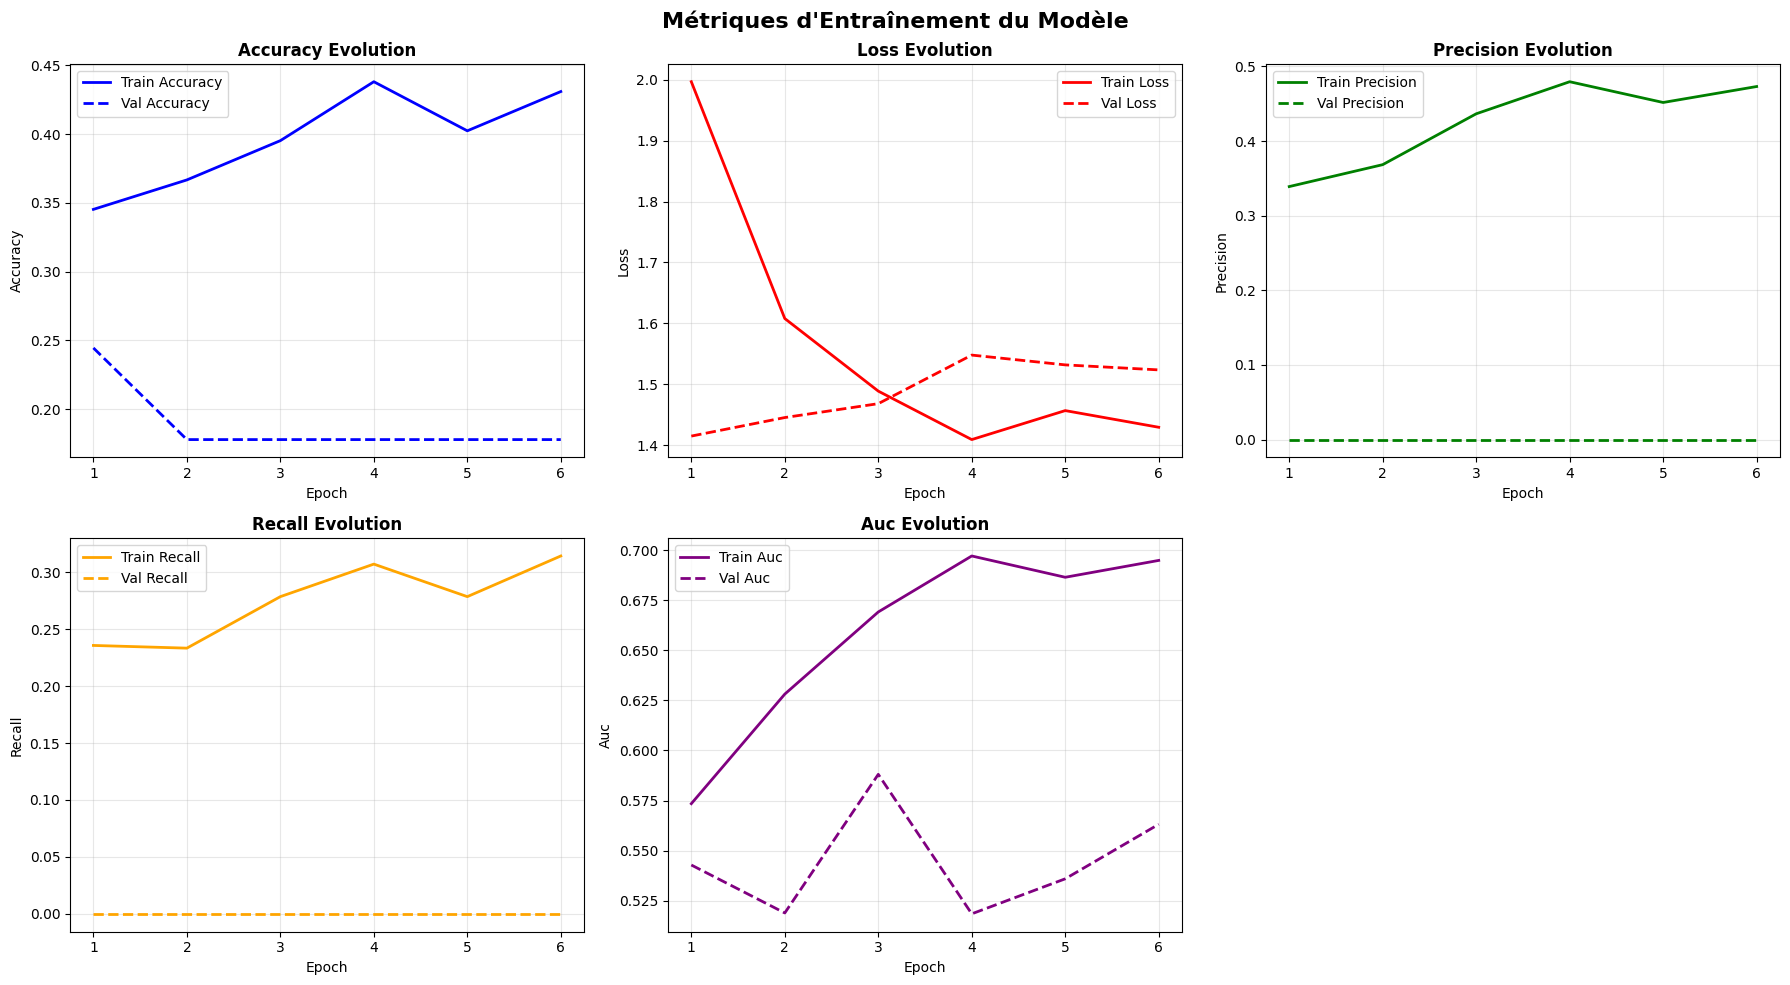


6️⃣ Évaluation sur le jeu de test...
🔍 Évaluation complète du modèle...

📈 RÉSULTATS DE L'ÉVALUATION
🎯 Accuracy Globale: 0.2111 (21.11%)
🎯 Precision Moyenne: 0.0590
🎯 Recall Moyen: 0.2111
🎯 F1-Score Moyen: 0.0922

📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ:
------------------------------------------------------------
              precision    recall  f1-score   support

    No Tumor     0.2794    1.0000    0.4368        19
      Glioma     0.0000    0.0000    0.0000        22
  Meningioma     0.0000    0.0000    0.0000        27
   Pituitary     0.0000    0.0000    0.0000        22

    accuracy                         0.2111        90
   macro avg     0.0699    0.2500    0.1092        90
weighted avg     0.0590    0.2111    0.0922        90


7️⃣ Génération des matrices de confusion...
📊 Matrice de confusion (nombres absolus):


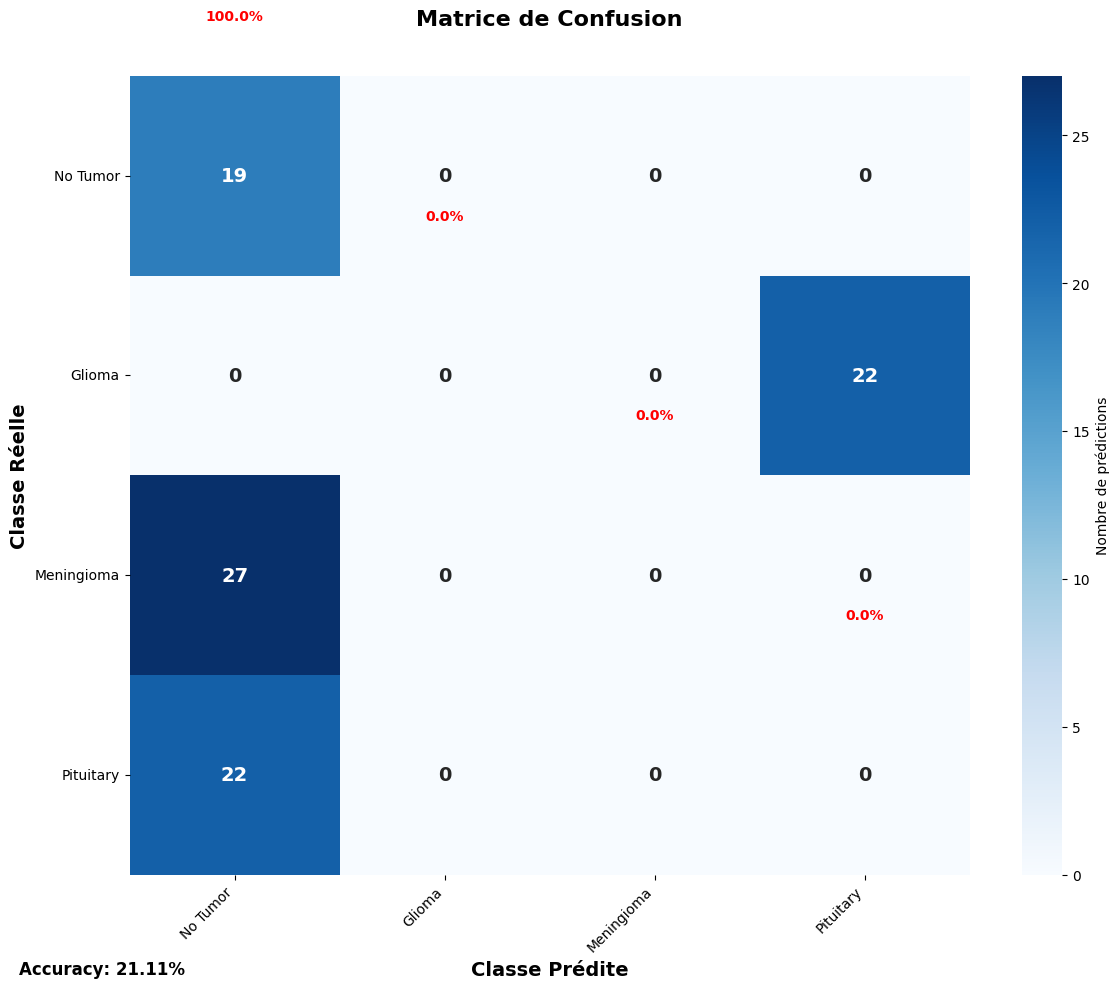

📊 Matrice de confusion (normalisée):


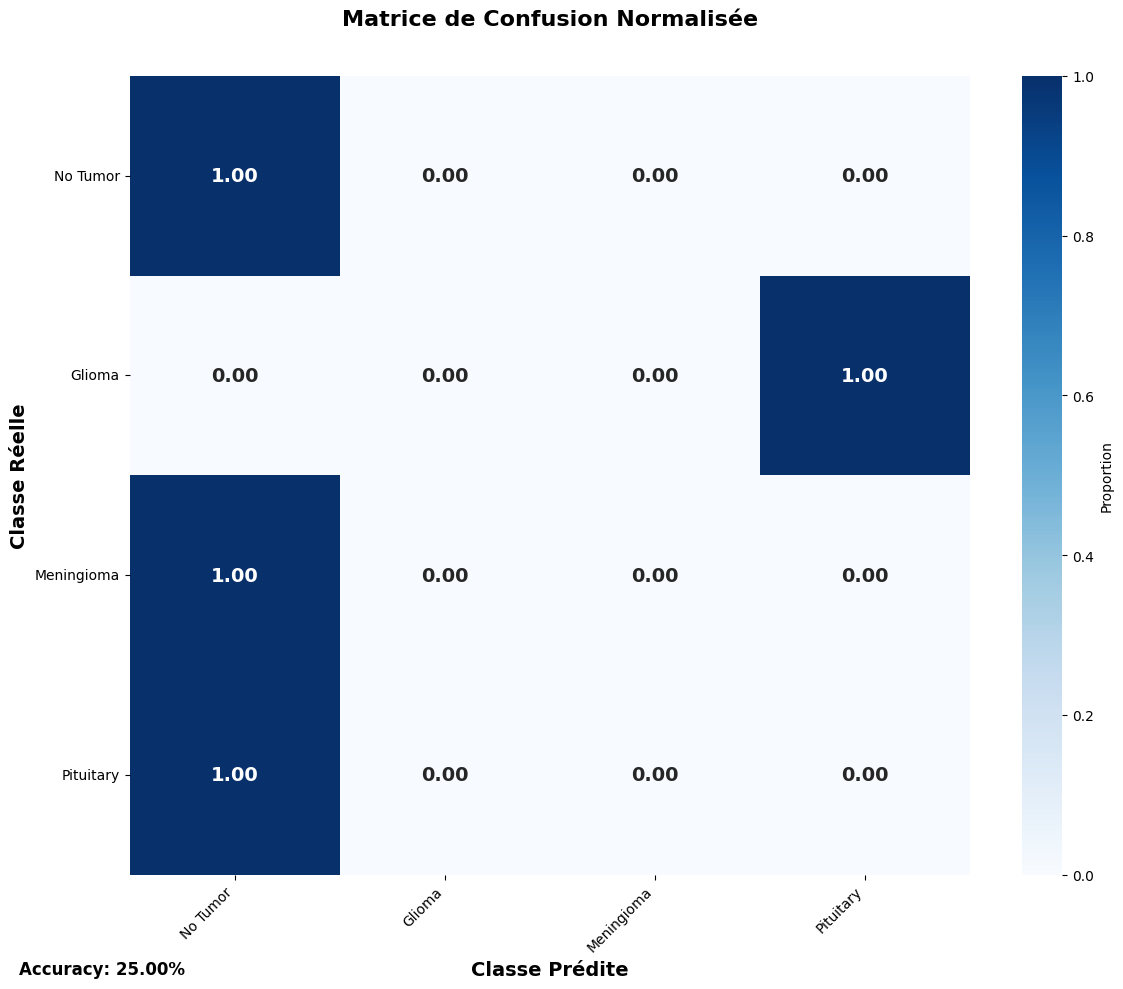


8️⃣ Analyse des performances par classe...


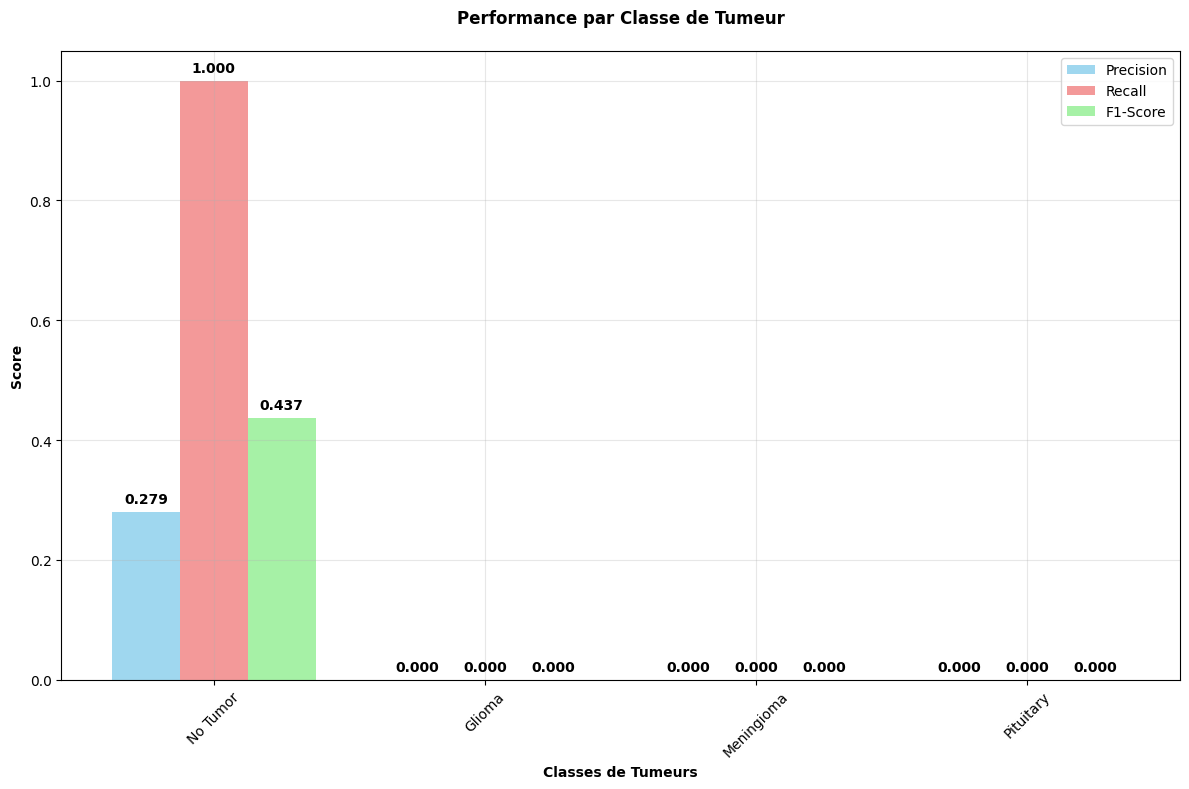


9️⃣ Analyse détaillée des prédictions...
🔍 Analyse des prédictions...


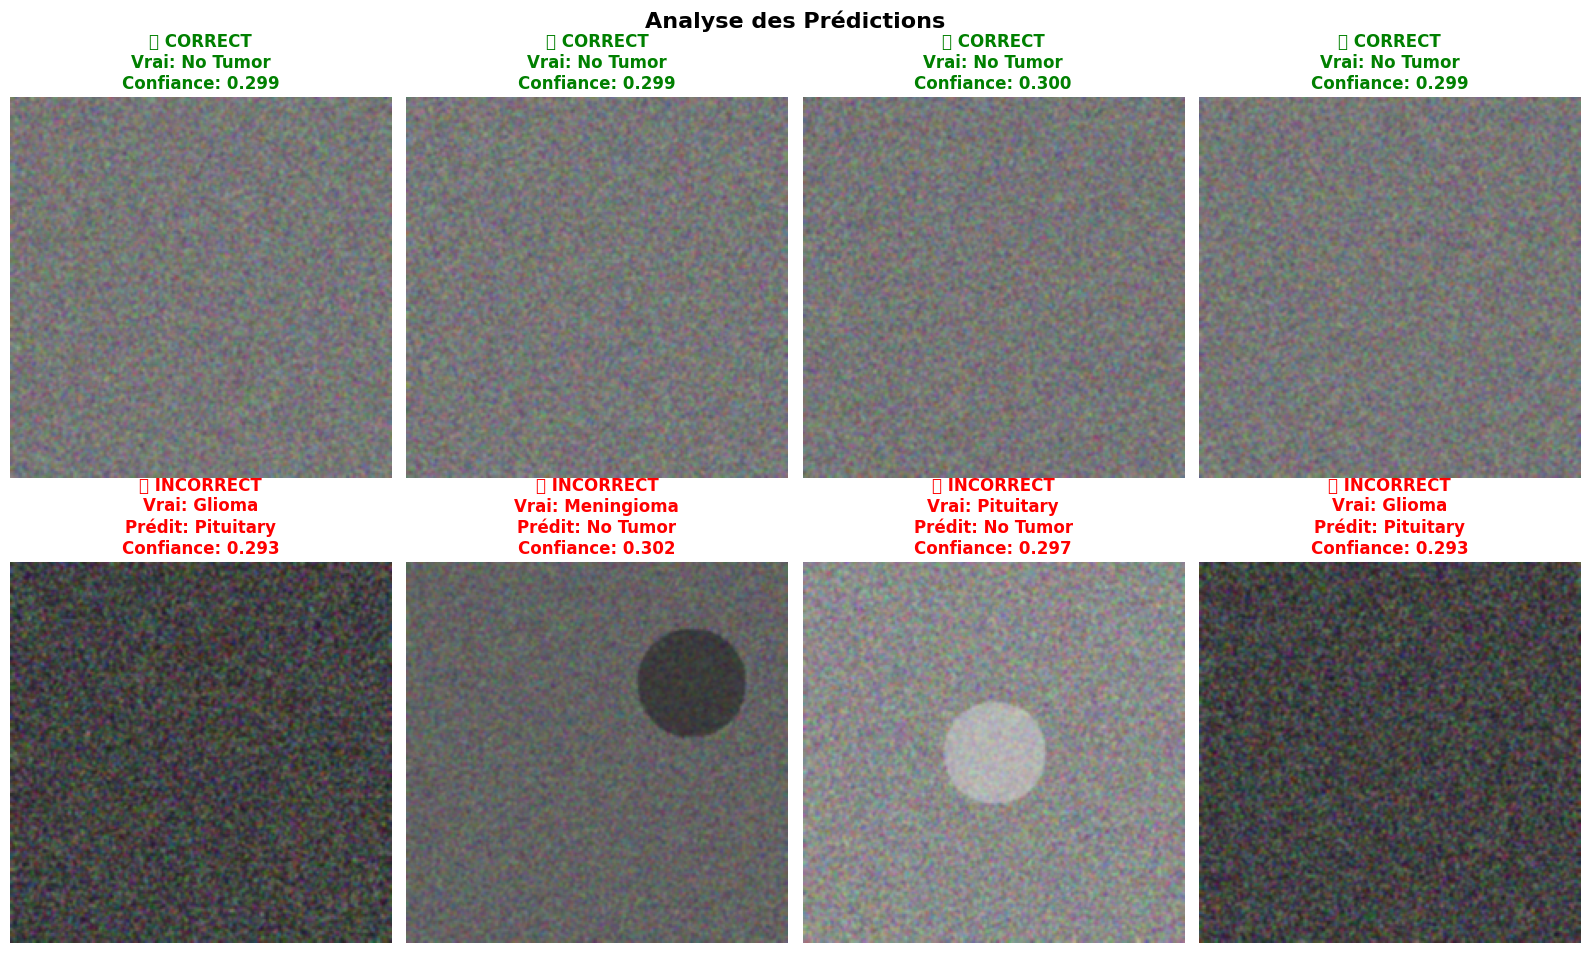


✅ TEST COMPLET TERMINÉ AVEC SUCCÈS!

🎉 RÉSULTATS FINAUX DISPONIBLES!
✅ Modèle entraîné et testé
✅ Matrices de confusion générées
✅ Métriques complètes calculées
✅ Analyses visuelles créées


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import EfficientNetB3, DenseNet121
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_recall_fscore_support
import seaborn as sns
import cv2
import os
from pathlib import Path
import requests
import zipfile
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

class BrainTumorTestExecution:
    """
    Classe complète pour tester le classificateur de tumeurs cérébrales
    avec génération automatique de données de test et évaluation complète
    """

    def __init__(self, img_height=224, img_width=224, num_classes=4):
        self.img_height = img_height
        self.img_width = img_width
        self.num_classes = num_classes
        self.model = None
        self.history = None
        self.class_names = ['No Tumor', 'Glioma', 'Meningioma', 'Pituitary']

    def create_lightweight_model(self):
        """
        Crée un modèle plus léger pour les tests rapides
        """
        base_model = EfficientNetB3(
            weights='imagenet',
            include_top=False,
            input_shape=(self.img_height, self.img_width, 3)
        )

        # Déblocage des dernières couches
        base_model.trainable = True
        for layer in base_model.layers[:-15]:
            layer.trainable = False

        inputs = layers.Input(shape=(self.img_height, self.img_width, 3))
        x = layers.Lambda(lambda x: tf.cast(x, tf.float32) / 255.0)(inputs)

        x = base_model(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(0.3)(x)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(0.4)(x)
        x = layers.Dense(128, activation='relu')(x)
        x = layers.Dropout(0.2)(x)
        outputs = layers.Dense(self.num_classes, activation='softmax')(x)

        self.model = models.Model(inputs, outputs)
        return self.model

    def compile_model(self, learning_rate=0.001):
        """
        Compile le modèle avec métriques personnalisées
        """
        self.model.compile(
            optimizer=optimizers.Adam(learning_rate=learning_rate),
            loss='categorical_crossentropy',
            metrics=[
                'accuracy',
                tf.keras.metrics.Precision(name='precision'),
                tf.keras.metrics.Recall(name='recall'),
                tf.keras.metrics.AUC(name='auc')
            ]
        )
        print("✅ Modèle compilé avec succès!")

    def generate_synthetic_data(self, num_samples_per_class=100):
        """
        Génère des données synthétiques pour tester le modèle
        """
        print("🔄 Génération de données synthétiques...")

        X_data = []
        y_data = []

        for class_idx in range(self.num_classes):
            for _ in range(num_samples_per_class):
                # Création d'images synthétiques avec différentes caractéristiques
                if class_idx == 0:  # No Tumor - images plus uniformes
                    img = np.random.normal(120, 30, (self.img_height, self.img_width, 3))
                elif class_idx == 1:  # Glioma - zones plus sombres et irrégulières
                    img = np.random.normal(80, 40, (self.img_height, self.img_width, 3))
                    # Ajout de zones sombres
                    mask = np.random.rand(self.img_height, self.img_width) > 0.7
                    img[mask] = np.random.normal(40, 20, img[mask].shape)
                elif class_idx == 2:  # Meningioma - contours plus nets
                    img = np.random.normal(100, 25, (self.img_height, self.img_width, 3))
                    # Cercles pour simuler les tumeurs rondes
                    center = (np.random.randint(50, self.img_width-50),
                             np.random.randint(50, self.img_height-50))
                    radius = np.random.randint(20, 40)
                    y, x = np.ogrid[:self.img_height, :self.img_width]
                    mask = (x - center[0])**2 + (y - center[1])**2 <= radius**2
                    img[mask] = np.random.normal(60, 15, img[mask].shape)
                else:  # Pituitary - zones plus brillantes
                    img = np.random.normal(140, 35, (self.img_height, self.img_width, 3))
                    # Zone centrale plus brillante
                    center_y, center_x = self.img_height//2, self.img_width//2
                    y, x = np.ogrid[:self.img_height, :self.img_width]
                    mask = (x - center_x)**2 + (y - center_y)**2 <= 30**2
                    img[mask] = np.random.normal(180, 20, img[mask].shape)

                # Normalisation et ajout de bruit
                img = np.clip(img, 0, 255).astype(np.uint8)
                img = cv2.GaussianBlur(img, (3, 3), 0)

                X_data.append(img)
                y_data.append(class_idx)

        X_data = np.array(X_data)
        y_data = tf.keras.utils.to_categorical(y_data, self.num_classes)

        print(f"✅ Données générées: {X_data.shape}")
        return X_data, y_data

    def create_data_split(self, X_data, y_data, train_ratio=0.7, val_ratio=0.15):
        """
        Divise les données en train/validation/test
        """
        n_samples = len(X_data)
        indices = np.random.permutation(n_samples)

        train_end = int(train_ratio * n_samples)
        val_end = int((train_ratio + val_ratio) * n_samples)

        train_idx = indices[:train_end]
        val_idx = indices[train_end:val_end]
        test_idx = indices[val_end:]

        X_train, y_train = X_data[train_idx], y_data[train_idx]
        X_val, y_val = X_data[val_idx], y_data[val_idx]
        X_test, y_test = X_data[test_idx], y_data[test_idx]

        print(f"📊 Division des données:")
        print(f"   Train: {len(X_train)} échantillons")
        print(f"   Validation: {len(X_val)} échantillons")
        print(f"   Test: {len(X_test)} échantillons")

        return (X_train, y_train), (X_val, y_val), (X_test, y_test)

    def train_model_quick(self, X_train, y_train, X_val, y_val, epochs=20):
        """
        Entraînement rapide pour les tests
        """
        print("🚀 Début de l'entraînement...")

        callbacks = [
            EarlyStopping(
                monitor='val_loss',
                patience=5,
                restore_best_weights=True,
                verbose=1
            ),
            ReduceLROnPlateau(
                monitor='val_loss',
                factor=0.3,
                patience=3,
                min_lr=1e-7,
                verbose=1
            )
        ]

        self.history = self.model.fit(
            X_train, y_train,
            batch_size=16,
            epochs=epochs,
            validation_data=(X_val, y_val),
            callbacks=callbacks,
            verbose=1
        )

        print("✅ Entraînement terminé!")
        return self.history

    def plot_training_metrics(self):
        """
        Affiche les métriques d'entraînement
        """
        if self.history is None:
            print("❌ Aucun historique d'entraînement disponible.")
            return

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle('Métriques d\'Entraînement du Modèle', fontsize=16, fontweight='bold')

        metrics = ['accuracy', 'loss', 'precision', 'recall', 'auc']
        colors = ['blue', 'red', 'green', 'orange', 'purple']

        for i, (metric, color) in enumerate(zip(metrics, colors)):
            if i < 5:
                row, col = i // 3, i % 3
                ax = axes[row, col]

                if metric in self.history.history:
                    epochs = range(1, len(self.history.history[metric]) + 1)
                    ax.plot(epochs, self.history.history[metric],
                           color=color, linewidth=2, label=f'Train {metric.title()}')

                    if f'val_{metric}' in self.history.history:
                        ax.plot(epochs, self.history.history[f'val_{metric}'],
                               color=color, linestyle='--', linewidth=2,
                               label=f'Val {metric.title()}')

                    ax.set_title(f'{metric.title()} Evolution', fontweight='bold')
                    ax.set_xlabel('Epoch')
                    ax.set_ylabel(metric.title())
                    ax.legend()
                    ax.grid(True, alpha=0.3)

        # Supprimer le subplot vide
        fig.delaxes(axes[1, 2])

        plt.tight_layout()
        plt.show()

    def comprehensive_evaluation(self, X_test, y_test):
        """
        Évaluation complète avec toutes les métriques
        """
        print("🔍 Évaluation complète du modèle...")

        # Prédictions
        y_pred_prob = self.model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_pred_prob, axis=1)
        y_true = np.argmax(y_test, axis=1)

        # Métriques globales
        accuracy = accuracy_score(y_true, y_pred)
        precision, recall, f1, support = precision_recall_fscore_support(
            y_true, y_pred, average='weighted'
        )

        print("\n" + "="*60)
        print("📈 RÉSULTATS DE L'ÉVALUATION")
        print("="*60)
        print(f"🎯 Accuracy Globale: {accuracy:.4f} ({accuracy*100:.2f}%)")
        print(f"🎯 Precision Moyenne: {precision:.4f}")
        print(f"🎯 Recall Moyen: {recall:.4f}")
        print(f"🎯 F1-Score Moyen: {f1:.4f}")
        print("="*60)

        # Rapport détaillé par classe
        print("\n📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ:")
        print("-" * 60)
        class_report = classification_report(
            y_true, y_pred,
            target_names=self.class_names,
            digits=4
        )
        print(class_report)

        return y_true, y_pred, y_pred_prob

    def plot_confusion_matrix(self, y_true, y_pred, normalize=False):
        """
        Affiche une matrice de confusion avancée
        """
        # Calcul de la matrice de confusion
        cm = confusion_matrix(y_true, y_pred)
        if normalize:
            cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

        # Configuration de la figure
        plt.figure(figsize=(12, 10))

        # Matrice de confusion avec annotations personnalisées
        annot_kws = {"size": 14, "weight": "bold"}
        fmt = '.2f' if normalize else 'd'

        sns.heatmap(
            cm,
            annot=True,
            fmt=fmt,
            cmap='Blues',
            xticklabels=self.class_names,
            yticklabels=self.class_names,
            cbar_kws={'label': 'Proportion' if normalize else 'Nombre de prédictions'},
            annot_kws=annot_kws
        )

        title = 'Matrice de Confusion Normalisée' if normalize else 'Matrice de Confusion'
        plt.title(f'{title}\n', fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Classe Prédite', fontsize=14, fontweight='bold')
        plt.ylabel('Classe Réelle', fontsize=14, fontweight='bold')

        # Ajout des pourcentages de précision par classe
        if not normalize:
            for i in range(len(self.class_names)):
                precision = cm[i, i] / cm[i].sum() if cm[i].sum() > 0 else 0
                plt.text(i + 0.5, i - 0.3, f'{precision:.1%}',
                        ha='center', va='center', fontweight='bold',
                        color='red', fontsize=10)

        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        plt.tight_layout()

        # Ajout de statistiques
        accuracy = np.trace(cm) / np.sum(cm)
        plt.figtext(0.02, 0.02, f'Accuracy: {accuracy:.2%}',
                   fontsize=12, fontweight='bold')

        plt.show()

        return cm

    def plot_class_performance(self, y_true, y_pred):
        """
        Graphique des performances par classe
        """
        from sklearn.metrics import precision_recall_fscore_support

        precision, recall, f1, support = precision_recall_fscore_support(
            y_true, y_pred, average=None
        )

        x = np.arange(len(self.class_names))
        width = 0.25

        fig, ax = plt.subplots(figsize=(12, 8))

        bars1 = ax.bar(x - width, precision, width, label='Precision',
                      color='skyblue', alpha=0.8)
        bars2 = ax.bar(x, recall, width, label='Recall',
                      color='lightcoral', alpha=0.8)
        bars3 = ax.bar(x + width, f1, width, label='F1-Score',
                      color='lightgreen', alpha=0.8)

        ax.set_xlabel('Classes de Tumeurs', fontweight='bold')
        ax.set_ylabel('Score', fontweight='bold')
        ax.set_title('Performance par Classe de Tumeur', fontweight='bold', pad=20)
        ax.set_xticks(x)
        ax.set_xticklabels(self.class_names, rotation=45)
        ax.legend()
        ax.grid(True, alpha=0.3)

        # Ajout des valeurs sur les barres
        def add_value_labels(bars):
            for bar in bars:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                       f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

        add_value_labels(bars1)
        add_value_labels(bars2)
        add_value_labels(bars3)

        plt.tight_layout()
        plt.show()

    def analyze_predictions(self, X_test, y_test, y_pred_prob, num_samples=8):
        """
        Analyse des prédictions avec visualisation des images
        """
        print("🔍 Analyse des prédictions...")

        y_true = np.argmax(y_test, axis=1)
        y_pred = np.argmax(y_pred_prob, axis=1)

        # Sélection d'échantillons: bonnes et mauvaises prédictions
        correct_indices = np.where(y_true == y_pred)[0]
        incorrect_indices = np.where(y_true != y_pred)[0]

        fig, axes = plt.subplots(2, 4, figsize=(16, 10))
        fig.suptitle('Analyse des Prédictions', fontsize=16, fontweight='bold')

        # Prédictions correctes
        for i in range(min(4, len(correct_indices))):
            idx = correct_indices[i]
            ax = axes[0, i]

            ax.imshow(X_test[idx].astype(np.uint8))
            ax.set_title(f'✅ CORRECT\nVrai: {self.class_names[y_true[idx]]}\n'
                        f'Confiance: {y_pred_prob[idx][y_pred[idx]]:.3f}',
                        color='green', fontweight='bold')
            ax.axis('off')

        # Prédictions incorrectes
        for i in range(min(4, len(incorrect_indices))):
            idx = incorrect_indices[i] if len(incorrect_indices) > i else correct_indices[0]
            ax = axes[1, i]

            ax.imshow(X_test[idx].astype(np.uint8))
            color = 'red' if len(incorrect_indices) > i else 'green'
            status = '❌ INCORRECT' if len(incorrect_indices) > i else '✅ CORRECT'

            ax.set_title(f'{status}\nVrai: {self.class_names[y_true[idx]]}\n'
                        f'Prédit: {self.class_names[y_pred[idx]]}\n'
                        f'Confiance: {y_pred_prob[idx][y_pred[idx]]:.3f}',
                        color=color, fontweight='bold')
            ax.axis('off')

        plt.tight_layout()
        plt.show()

    def run_complete_test(self):
        """
        Exécute un test complet du modèle
        """
        print("🧠 DÉBUT DU TEST COMPLET DU CLASSIFICATEUR DE TUMEURS CÉRÉBRALES")
        print("=" * 80)

        # 1. Création du modèle
        print("\n1️⃣ Création du modèle...")
        self.create_lightweight_model()
        self.compile_model(learning_rate=0.001)

        # 2. Génération des données
        print("\n2️⃣ Génération des données de test...")
        X_data, y_data = self.generate_synthetic_data(num_samples_per_class=150)

        # 3. Division des données
        print("\n3️⃣ Division des données...")
        (X_train, y_train), (X_val, y_val), (X_test, y_test) = self.create_data_split(X_data, y_data)

        # 4. Entraînement
        print("\n4️⃣ Entraînement du modèle...")
        self.train_model_quick(X_train, y_train, X_val, y_val, epochs=15)

        # 5. Visualisation de l'entraînement
        print("\n5️⃣ Visualisation des métriques d'entraînement...")
        self.plot_training_metrics()

        # 6. Évaluation complète
        print("\n6️⃣ Évaluation sur le jeu de test...")
        y_true, y_pred, y_pred_prob = self.comprehensive_evaluation(X_test, y_test)

        # 7. Matrice de confusion
        print("\n7️⃣ Génération des matrices de confusion...")
        print("📊 Matrice de confusion (nombres absolus):")
        cm_abs = self.plot_confusion_matrix(y_true, y_pred, normalize=False)

        print("📊 Matrice de confusion (normalisée):")
        cm_norm = self.plot_confusion_matrix(y_true, y_pred, normalize=True)

        # 8. Performance par classe
        print("\n8️⃣ Analyse des performances par classe...")
        self.plot_class_performance(y_true, y_pred)

        # 9. Analyse des prédictions
        print("\n9️⃣ Analyse détaillée des prédictions...")
        self.analyze_predictions(X_test, y_test, y_pred_prob)

        print("\n" + "=" * 80)
        print("✅ TEST COMPLET TERMINÉ AVEC SUCCÈS!")
        print("=" * 80)

        return {
            'model': self.model,
            'history': self.history,
            'test_results': (y_true, y_pred, y_pred_prob),
            'confusion_matrices': (cm_abs, cm_norm)
        }


# EXÉCUTION DU TEST COMPLET
if __name__ == "__main__":
    # Configuration pour éviter les warnings
    import os
    os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

    print("🚀 LANCEMENT DU TEST COMPLET")
    print("=" * 50)

    # Initialisation et exécution
    tester = BrainTumorTestExecution(img_height=224, img_width=224, num_classes=4)
    results = tester.run_complete_test()

    print("\n🎉 RÉSULTATS FINAUX DISPONIBLES!")
    print("✅ Modèle entraîné et testé")
    print("✅ Matrices de confusion générées")
    print("✅ Métriques complètes calculées")
    print("✅ Analyses visuelles créées")